# Tiny CDSE test: input scales and UDF runs

Data: `tmp/cdse_tiny/<name>/*.nc`, produced by `scripts/validation/cdse_tiny_inputs.py`.
- **AOI:** 1.5 x 1.5 km, 3 x 3 MODIS pixels, in the Senales valley.
- **Period:** Oct 2022 - Aug 2023.

The notebook has three parts:
1. The raw inputs, without scaling, to check units and scale factors.
2. The pipeline intermediates, which are the UDF inputs.
3. The SCA and SWE UDFs run locally on those inputs, compared with the backend runs.

## 0. Run the tiny jobs on CDSE

Job definitions (extent, period, cubes) live in `scripts/validation/cdse_tiny_inputs.py`. Job ids are stored in `tmp/cdse_tiny/jobs.json`, so rerunning these cells resumes instead of resubmitting. To resubmit a cube, delete its entry from `jobs.json` and its folder.

1. **Submit:** creates and starts the missing jobs.
2. **Status/download:** downloads finished jobs without blocking. Rerun it until every cube is downloaded.

In [ ]:
import sys
from pathlib import Path

_root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').exists())
for p in (_root / 'src', _root / 'scripts' / 'validation'):
    if str(p) not in sys.path:
        sys.path.insert(0, str(p))

import cdse_tiny_inputs as tiny  # authenticates on import

NAMES = list(tiny.CUBES)  # or a subset, e.g. ['raw_dem', 'sca']
tiny.submit(NAMES)

Authenticated using refresh token.


bands_from_stac_collection: consulting items for band metadata
bands_from_stac_collection: consulting items for band metadata
Failed to extract cube metadata from STAC URL https://openeo.dataspace.copernicus.eu/openeo/1.2/jobs/j-26111516215247978f1de7628edcd235/results/YTQyMWY4NDktMmFlNi00MmQzLTkzZjAtYjQzYWEyNTY3ZjFl/1a537cdc7cc07d45d21708df68af4a46?expires=1795607086
Traceback (most recent call last):
  File "c:\Users\VROMPAYH\AppData\Local\anaconda3\envs\mountains_snow\Lib\site-packages\pystac\link.py", line 339, in resolve_stac_object
    obj = stac_io.read_stac_object(target_href, root=root)
          ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\VROMPAYH\AppData\Local\anaconda3\envs\mountains_snow\Lib\site-packages\pystac\stac_io.py", line 234, in read_stac_object
    return self.stac_object_from_dict(
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\VROMPAYH\AppData\Local\anaconda3\envs\mountains_snow\Lib\site-packages\pystac\stac_io.py", line 179, in s

sca_inputs j-26111811453349a7be774ab2a3f7c217
sca_inputs error see sca_inputs_error.txt
sca SKIPPED: upstream not finished: ['sca_inputs']


In [5]:
NAMES = list(tiny.CUBES) 
tiny.download(NAMES, wait=False)  # wait=True blocks until every job is finished

swe_meteo running


In [1]:
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
from openeo.udf import UdfData, XarrayDataCube
from openeo.udf.run_code import run_udf_code

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').exists())
DATA = ROOT / 'tmp/cdse_tiny'
SCA_UDF = ROOT / 'src/openeo_mountains_snow/snow_cover_area/udfs/snow_cover_area_reconstruction_udf.py'
SWE_UDF = ROOT / 'src/openeo_mountains_snow/snow_water_equivalent/udfs/snow_water_equivalent_udf.py'
SOLAR_UDF = ROOT / 'src/openeo_mountains_snow/common/udfs/solar_position_udf.py'
INCIDENCE_UDF = ROOT / 'src/openeo_mountains_snow/common/udfs/incidence_angle_udf.py'


def load_tifs(files):
    """openEO GTiff results (one file per date, band names in the descriptions) -> Dataset."""
    import rasterio  # only needed for the GTiff results (chained cubes)
    parts = []
    for f in files:
        with rasterio.open(f) as src:
            a, t = src.read(), src.transform
            names = [d or f'band_{i + 1}' for i, d in enumerate(src.descriptions)]
        part = xr.Dataset({n: (('y', 'x'), a[i]) for i, n in enumerate(names)},
                          coords={'x': t.c + t.a * (np.arange(a.shape[2]) + 0.5),
                                  'y': t.f + t.e * (np.arange(a.shape[1]) + 0.5)})
        date = re.search(r'\d{4}-\d{2}-\d{2}', f.name)
        parts.append(part.expand_dims(t=[pd.Timestamp(date.group())]) if date else part)
    return xr.concat(parts, 't') if len(parts) > 1 else parts[0]


def load(name):
    files = sorted((DATA / name).glob('*.nc'))
    tifs = sorted((DATA / name).glob('*.tif'))
    if not files and not tifs:
        print(f'{name}: not downloaded', *(DATA.glob(f'{name}_error.txt')))
        return None
    try:
        if not files:
            return load_tifs(tifs)
        ds = xr.open_mfdataset(files, combine='by_coords', mask_and_scale=False) if len(files) > 1 else xr.open_dataset(files[0], mask_and_scale=False)
        return ds.drop_vars('crs', errors='ignore').load()
    except Exception as e:
        print(f'{name}: cannot read ({type(e).__name__}: {e})')
        return None


def run_udf(path, cube, context=None, proj=None):
    data = UdfData(datacube_list=[XarrayDataCube(cube)], user_context=context or {}, proj=proj)
    return run_udf_code(code=Path(path).read_text(), data=data).get_datacube_list()[0].get_array()


def have(*names):
    """True if all cubes are loaded; otherwise print what is missing so the cell can be skipped."""
    missing = [n for n in names if ds.get(n) is None]
    if missing:
        print('SKIPPED, missing:', missing)
    return not missing


ds = {n: load(n) for n in ['raw_agera5', 'geopotential', 'raw_dem', 'raw_slope_aspect_vito', 'raw_modis',
                           'modis_scf', 'swe_meteo', 'snow', 'cp_occ', 'sca_inputs', 'sca', 'swe']}
for n, d in ds.items():
    if d is not None:
        print(f'{n}: {dict(d.sizes)} vars={list(d.data_vars)[:8]}{"..." if len(d.data_vars) > 8 else ""}')


swe_meteo: not downloaded c:\Git_projects\openeo_mountains_snow\tmp\cdse_tiny\swe_meteo_error.txt
sca_inputs: not downloaded
sca: not downloaded
swe: not downloaded
raw_agera5: {'t': 335, 'y': 1, 'x': 1} vars=['2m_temperature_min', '2m_temperature_max', '2m_temperature_mean', 'dewpoint_temperature_mean', 'vapour_pressure', 'wind_speed', 'solar_radiation_flux', 'total_precipitation']
geopotential: {'y': 5, 'x': 7} vars=['geopotential']
raw_dem: {'t': 1, 'y': 51, 'x': 73} vars=['DEM']
raw_slope_aspect_vito: {'t': 1, 'y': 52, 'x': 52} vars=['SLP30', 'ASP30']
raw_modis: {'t': 99, 'y': 150, 'x': 150} vars=['NDSI_Snow_Cover']
modis_scf: {'t': 99, 'y': 75, 'x': 75} vars=['scf']
snow: {'t': 131, 'y': 79, 'x': 79} vars=['snow']
cp_occ: {'y': 79, 'x': 79} vars=['cp_scf_0_10', 'cp_scf_10_20', 'cp_scf_20_30', 'cp_scf_30_40', 'cp_scf_40_50', 'cp_scf_50_60', 'cp_scf_60_70', 'cp_scf_70_80']...


## 1. Raw inputs as stored

Values are shown as stored, without `scale_factor` applied, because the pipeline does its own scaling.

In [34]:
rows = []
for n in ['raw_agera5', 'geopotential', 'raw_dem', 'raw_slope_aspect_vito', 'raw_modis']:
    if ds[n] is None:
        continue
    for v, a in ds[n].data_vars.items():
        x = a.values.astype(float)
        nodata = a.attrs.get('_FillValue', a.attrs.get('nodata'))
        if nodata is not None:
            x = np.where(x == float(nodata), np.nan, x)
        rows.append({'cube': n, 'band': v, 'dtype': str(a.dtype), 'min': np.nanmin(x), 'p50': np.nanmedian(x),
                     'max': np.nanmax(x), 'attrs': {k: a.attrs[k] for k in a.attrs if k in ('scale_factor', 'add_offset', 'units', '_FillValue', 'nodata')}})
raw_stats = pd.DataFrame(rows)
raw_stats


,cube,band,dtype,min,p50,max,attrs
0,raw_agera5,2m_temperature_min,float64,2.536700e+04,2.708100e+04,2.835400e+04,"{'units': '', '_FillValue': 4294967295.0}"
1,raw_agera5,2m_temperature_max,float64,2.593400e+04,2.778200e+04,2.951500e+04,"{'units': '', '_FillValue': 4294967295.0}"
2,raw_agera5,2m_temperature_mean,float64,0.000000e+00,2.743450e+04,2.897700e+04,"{'units': '', '_FillValue': 4294967295.0}"
3,raw_agera5,dewpoint_temperature_mean,float64,2.447400e+04,2.685700e+04,2.831000e+04,"{'units': '', '_FillValue': 4294967295.0}"
4,raw_agera5,vapour_pressure,float64,5.080000e+02,4.546000e+03,1.209000e+04,"{'units': '', '_FillValue': 4294967295.0}"
5,raw_agera5,wind_speed,float64,5.200000e+01,1.030000e+02,2.020000e+02,"{'units': '', '_FillValue': 4294967295.0}"
6,raw_agera5,solar_radiation_flux,float64,2.503136e+06,1.356740e+07,2.908746e+07,"{'units': '', '_FillValue': 4294967295.0}"
7,raw_agera5,total_precipitation,float64,0.000000e+00,1.140000e+02,4.322000e+03,"{'units': '', '_FillValue': 4294967295.0}"
8,geopotential,geopotential,float64,1.175109e+04,2.054349e+04,2.815962e+04,"{'units': 'm**2 s**-2', '_FillValue': nan}"
9,raw_dem,DEM,float32,1.953700e+03,2.211450e+03,2.761568e+03,"{'units': '', '_FillValue': nan}"


### AGERA5

The pipeline assumes:

| Band | Pipeline conversion |
|---|---|
| `2m_temperature_mean`, `dewpoint_temperature_mean` | x 0.01 = K |
| `total_precipitation` | x 0.01 = mm/day |
| `solar_radiation_flux` | J/m²/day, / 86400 = W/m² |

Expected for the Senales valley:
- **Annual precipitation:** about 500-1000 mm.
- **Daily-mean shortwave:** about 30-120 W/m² in winter and 200-330 W/m² in summer.

missing days: {'2m_temperature_max': ['2023-02-03'], '2m_temperature_mean': ['2023-01-13', '2023-05-04']}
T range -17.8..16.6 °C | precip total 1012 mm over 335 days, max 43.2 mm/day | SW 29..337 W/m²
monthly mean SW (W/m²): {1: 71.0, 2: 121.0, 3: 178.0, 4: 233.0, 5: 220.0, 6: 250.0, 7: 237.0, 8: 208.0, 10: 120.0, 11: 83.0, 12: 58.0}
other AGERA5 bands: ['2m_temperature_min', '2m_temperature_max', 'vapour_pressure', 'wind_speed']


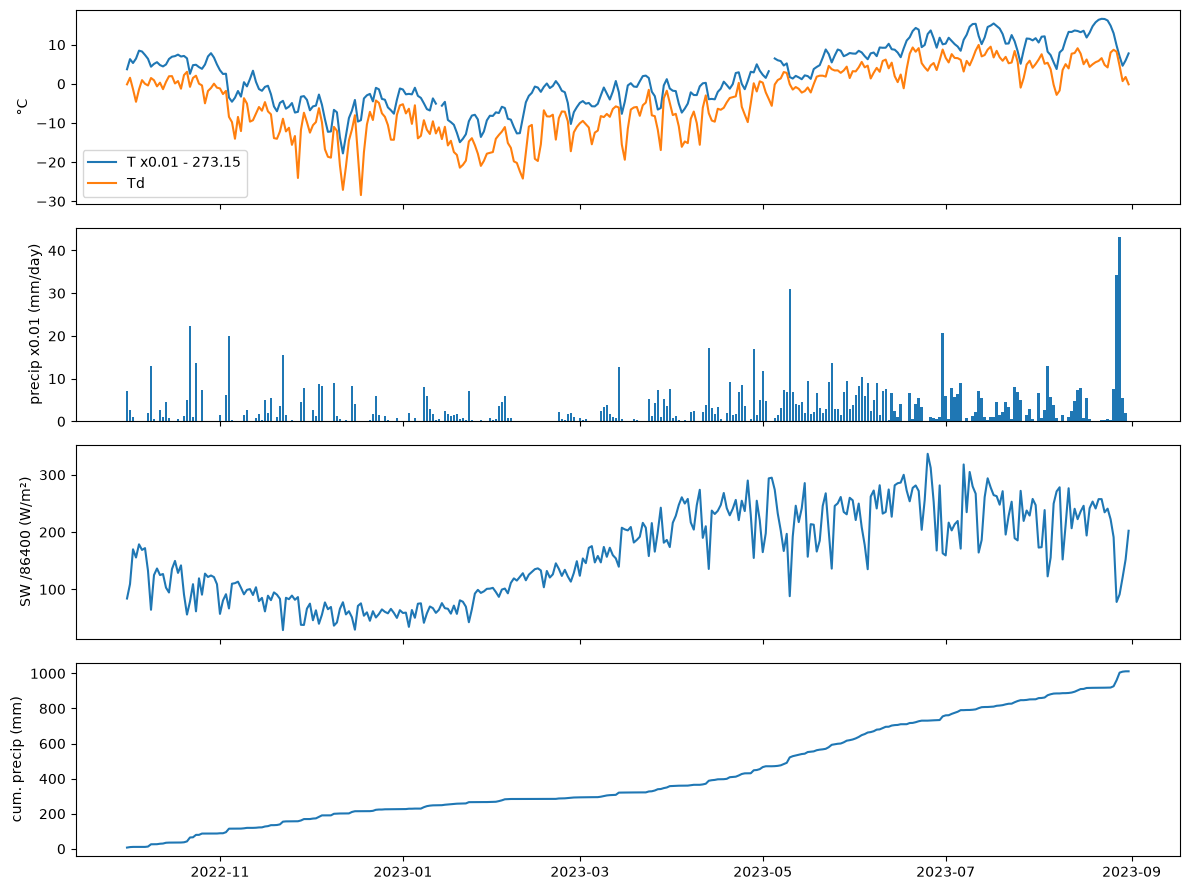

In [2]:
if have('raw_agera5'):
    ag = ds['raw_agera5']
    ag = ag.where(ag != ag['2m_temperature_mean'].attrs.get('_FillValue', 4294967295))  # uint32 nodata
    ag['2m_temperature_mean'] = ag['2m_temperature_mean'].where(ag['2m_temperature_mean'] > 0)  # 0 K = missing
    print('missing days:', {v: [str(t)[:10] for t in ag.t.values[ag[v].isnull().squeeze().values]] for v in ag.data_vars if ag[v].isnull().any()})
    ag_mean = ag.mean(['x', 'y'])
    t_c = ag_mean['2m_temperature_mean'] * 0.01 - 273.15
    td_c = ag_mean['dewpoint_temperature_mean'] * 0.01 - 273.15
    pr = ag_mean['total_precipitation'] * 0.01
    sw = ag_mean['solar_radiation_flux'] / 86400
    fig, axes = plt.subplots(4, 1, figsize=(12, 9), sharex=True)
    axes[0].plot(ag.t, t_c, label='T x0.01 - 273.15'); axes[0].plot(ag.t, td_c, label='Td'); axes[0].set_ylabel('°C'); axes[0].legend()
    axes[1].bar(ag.t, pr); axes[1].set_ylabel('precip x0.01 (mm/day)')
    axes[2].plot(ag.t, sw); axes[2].set_ylabel('SW /86400 (W/m²)')
    axes[3].plot(ag.t, pr.cumsum()); axes[3].set_ylabel('cum. precip (mm)')
    plt.tight_layout()
    print(f'T range {float(t_c.min()):.1f}..{float(t_c.max()):.1f} °C | precip total {float(pr.sum()):.0f} mm over {ag.sizes["t"]} days, '
          f'max {float(pr.max()):.1f} mm/day | SW {float(sw.min()):.0f}..{float(sw.max()):.0f} W/m²')
    sw_month = sw.groupby('t.month').mean().round(0).to_pandas()
    print('monthly mean SW (W/m²):', sw_month.to_dict())
    print('other AGERA5 bands:', [v for v in ag.data_vars if v not in ('2m_temperature_mean', 'dewpoint_temperature_mean', 'total_precipitation', 'solar_radiation_flux')])


### AGERA5 reference height and DEM

`geopotential` is the ERA5 surface geopotential `z` (m²/s², 0.1° grid with cell centres on the AGERA5 grid). It comes from `tmp/geopotential/geopotential.tif`, cropped around the AOI into `tmp/cdse_tiny/geopotential/openEO.nc`. The reference height is z / 9.80665.

The pipeline used `35885 / z`, which gives about 1.7 m at the AOI instead of about 2113 m. It now uses `z / 9.80665` in `downscale_variables.preprocess_low_resolution_agera`.

**TODO (\*):** on CDSE, `load_stac` of the geopotential item still fails with `NoDataAvailable` (`raw_geopotential`).


In [3]:
if have('raw_dem'):
    dem = ds['raw_dem']
    dem_v = dem[list(dem.data_vars)[0]].squeeze().values.astype(float)
    print(f'DEM (COPERNICUS_30): {np.nanmin(dem_v):.0f}..{np.nanmax(dem_v):.0f} m, mean {np.nanmean(dem_v):.0f} m')
if have('geopotential', 'raw_agera5'):
    rh = ds['geopotential']['geopotential'] / 9.80665
    print('ERA5 reference height z / g (m):\n', rh.round(0).to_pandas())
    ref_height = float(rh.sel(x=ag.x.item(), y=ag.y.item(), method='nearest'))
    print(f'AGERA5 pixel ({ag.x.item():.2f}, {ag.y.item():.2f}) -> reference height {ref_height:.0f} m '
          f'(old pipeline 35885 / z = {35885 / (ref_height * 9.80665):.2f} m)')


DEM (COPERNICUS_30): 1954..2762 m, mean 2221 m
ERA5 reference height z / g (m):
 x       10.5    10.6    10.7    10.8    10.9    11.0    11.1
y                                                           
46.9  2059.0  2342.0  2660.0  2871.0  2800.0  2553.0  2355.0
46.8  2066.0  2251.0  2609.0  2836.0  2794.0  2394.0  2066.0
46.7  1911.0  1859.0  2026.0  2113.0  2095.0  1762.0  1519.0
46.6  2145.0  2039.0  2009.0  1908.0  1783.0  1508.0  1198.0
46.5  2525.0  2572.0  2503.0  2275.0  1979.0  1637.0  1241.0
AGERA5 pixel (10.80, 46.70) -> reference height 2113 m (old pipeline 35885 / z = 1.73 m)


### Slope and aspect (VITO DEM_slope_30m / DEM_aspec_30m)

The stored values are compared, per pixel, with slope and aspect computed from the COPERNICUS_30 DEM. `incidence_angle_udf` passes them to `pvlib.irradiance.aoi`, which expects degrees.

Result on this AOI: `SLP30` = slope in degrees x 100, and `ASP30` = aspect in degrees clockwise from north (downslope). The pipeline passes `SLP30` unscaled, so the surface tilt is 100x too large.


VITO slope raw 163..4479 (median 2896); DEM slope 1.6..50.7 deg (median 29.5)
per-pixel median ratio VITO slope / DEM slope: 98.6  -> SLP30 = degrees x 100
VITO aspect raw 0..359; per-pixel VITO - DEM aspect: median -0.8 deg, |diff| p50 3.3, p90 11.0  -> ASP30 = degrees clockwise from north (downslope)


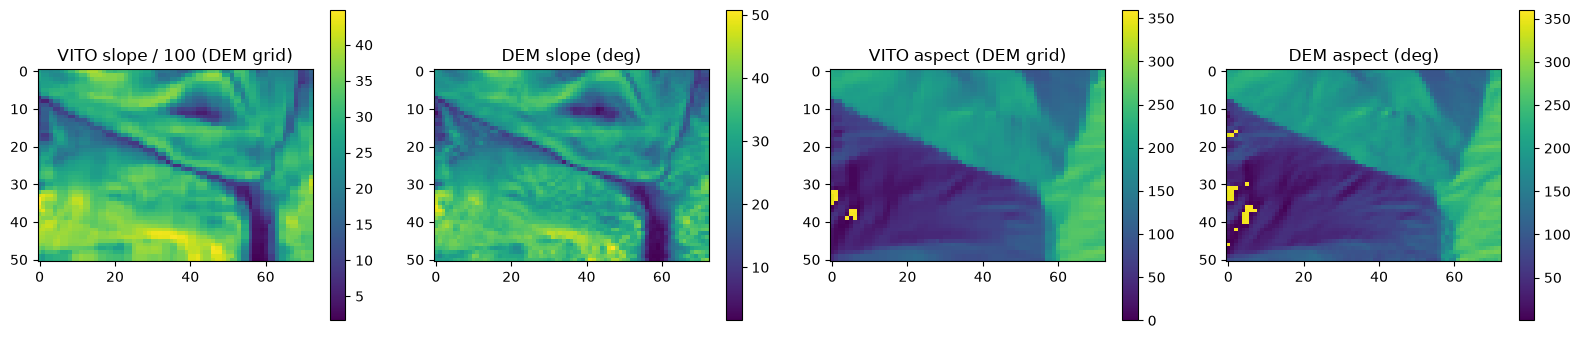

In [4]:
from pyproj import Transformer


def slope_aspect_deg(z, x, y):
    if abs(x[1] - x[0]) < 1:  # lat/lon grid -> metres
        lat = np.radians(np.mean(y))
        dx, dy = abs(x[1] - x[0]) * 111320 * np.cos(lat), abs(y[1] - y[0]) * 110540
    else:
        dx, dy = abs(x[1] - x[0]), abs(y[1] - y[0])
    dzdy, dzdx = np.gradient(z, dy, dx)  # rows go north -> south, so dzdy = dz/d(south)
    slope = np.degrees(np.arctan(np.hypot(dzdx, dzdy)))
    aspect = np.degrees(np.arctan2(-dzdx, dzdy)) % 360  # downslope direction, clockwise from north
    return slope, aspect


def vito_on_dem_grid(sa, dem):
    """Nearest VITO (EPSG:3035) pixel for each DEM (EPSG:4326) pixel."""
    lon, lat = np.meshgrid(dem.x.values, dem.y.values)
    ex, ny = Transformer.from_crs('EPSG:4326', 'EPSG:3035', always_xy=True).transform(lon, lat)
    pts = dict(x=xr.DataArray(ex, dims=('y', 'x')), y=xr.DataArray(ny, dims=('y', 'x')))
    out = sa.squeeze('t', drop=True).sel(**pts, method='nearest').astype(float)
    return out.assign_coords(x=dem.x.values, y=dem.y.values)


if have('raw_slope_aspect_vito', 'raw_dem'):
    sa = ds['raw_slope_aspect_vito']
    slope_raw, aspect_raw = sa['SLP30'].squeeze().values.astype(float), sa['ASP30'].squeeze().values.astype(float)
    slope_dem, aspect_dem = slope_aspect_deg(dem_v, dem.x.values, dem.y.values)
    sa_dem = vito_on_dem_grid(sa, dem)  # VITO values on the DEM grid
    d_aspect = (sa_dem['ASP30'].values - aspect_dem + 180) % 360 - 180
    print(f'VITO slope raw {np.nanmin(slope_raw):.0f}..{np.nanmax(slope_raw):.0f} (median {np.nanmedian(slope_raw):.0f}); '
          f'DEM slope {np.nanmin(slope_dem):.1f}..{np.nanmax(slope_dem):.1f} deg (median {np.nanmedian(slope_dem):.1f})')
    print(f'per-pixel median ratio VITO slope / DEM slope: {np.nanmedian(sa_dem["SLP30"].values / slope_dem):.1f}  -> SLP30 = degrees x 100')
    print(f'VITO aspect raw {np.nanmin(aspect_raw):.0f}..{np.nanmax(aspect_raw):.0f}; per-pixel VITO - DEM aspect: '
          f'median {np.nanmedian(d_aspect):.1f} deg, |diff| p50 {np.nanmedian(np.abs(d_aspect)):.1f}, p90 {np.nanpercentile(np.abs(d_aspect), 90):.1f}'
          '  -> ASP30 = degrees clockwise from north (downslope)')
    fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
    for ax, (title, a) in zip(axes, [('VITO slope / 100 (DEM grid)', sa_dem['SLP30'] / 100), ('DEM slope (deg)', slope_dem),
                                     ('VITO aspect (DEM grid)', sa_dem['ASP30']), ('DEM aspect (deg)', aspect_dem)]):
        im = ax.imshow(a); ax.set_title(title); plt.colorbar(im, ax=ax)
    plt.tight_layout()


### MODIS MOD10A1 NDSI_Snow_Cover

Valid NDSI values are 0-100. Values above 100 are flags: 200 missing, 201 no decision, 211 night, 237 inland water, 239 ocean, 250 cloud, 254 detector saturated, 255 fill.

In [5]:
if have('raw_modis'):
    m = ds['raw_modis'][list(ds['raw_modis'].data_vars)[0]].values.astype(np.uint8)  # stored as int8: 250 (cloud) reads as -6
    vals, counts = np.unique(m, return_counts=True)
    flags = {int(v): int(c) for v, c in zip(vals, counts) if v > 100}
    print(f'days: {ds["raw_modis"].sizes["t"]} | valid 0..100 share: {np.mean(m <= 100):.2f} | flags: {flags}')
if have('modis_scf'):
    scf = ds['modis_scf']['scf'].values
    print('pipeline modis_scf:', {k: int(v) for k, v in zip(*np.unique(np.where(np.isnan(scf), -1, np.where(scf > 100, scf, 1)), return_counts=True))},
          '(1 = valid 0..100, -1 = NaN)', f'| valid range {np.nanmin(np.where(scf <= 100, scf, np.nan)):.1f}..{np.nanmax(np.where(scf <= 100, scf, np.nan)):.1f}')
if have('raw_modis', 'modis_scf'):
    print(f'cloud/flag share per cube: raw {np.mean(m > 100):.3f}, modis_scf {np.mean(scf == 205):.3f}')


days: 99 | valid 0..100 share: 0.45 | flags: {250: 1230048}
pipeline modis_scf: {np.float32(1.0): 249326, np.float32(205.0): 307549} (1 = valid 0..100, -1 = NaN) | valid range 0.0..100.0
cloud/flag share per cube: raw 0.552, modis_scf 0.552


## 2. Pipeline intermediates (UDF inputs)

### SWE meteo rebuilt offline

The backend `swe_meteo` job failed, so `swe_meteo_cube` is reproduced here from `raw_agera5`, `geopotential`, `raw_dem` and `raw_slope_aspect_vito`, on the DEM grid:
- **Temperature:** `T x 0.01` lifted to sea level from the reference height z / 9.80665, then lowered to the DEM with the pipeline lapse rate `lapse_rate_sohem[1]` = 8.1 K/km.
- **Precipitation:** `x 0.01` mm/day. The AOI holds one AGERA5 pixel, so bilinear resampling gives a constant field.
- **Shortwave:** `/ 86400` W/m², then the solar-position UDF (no S2 context, so local solar noon) and the incidence-angle UDF. Slope is `SLP30 x SLOPE_SCALE`. `sw_as_is` keeps the pipeline's unscaled slope for comparison.

Days with missing AGERA5 temperature stay NaN.


In [6]:
LAPSE = 8.1e-3      # K/m, lapse_rate_sohem[1] as in downscale_temperature_humidity
SLOPE_SCALE = 0.01  # VITO SLP30 = degrees x 100; the pipeline uses 1 (unscaled)


def on_grid(a, grid):
    """Single AGERA5 pixel -> grid (what bilinear resampling of one pixel gives)."""
    return a.squeeze(['x', 'y'], drop=True).expand_dims(y=grid.y.values, x=grid.x.values).transpose('t', 'y', 'x')


def shortwave(flux, sun, sa_dem, slope_scale):
    static = [(sa_dem['ASP30'], 'aspect'), (sa_dem['SLP30'] * slope_scale, 'slope')]
    cube = xr.concat([flux.expand_dims(bands=['solar-radiation-flux'], axis=1), sun]
                     + [a.expand_dims(t=flux.t.values, bands=[b]).transpose('t', 'bands', 'y', 'x') for a, b in static], dim='bands')
    return run_udf(INCIDENCE_UDF, cube).isel(bands=0, drop=True)


if ds['swe_meteo'] is None and have('raw_agera5', 'geopotential', 'raw_dem', 'raw_slope_aspect_vito'):
    z = dem['DEM'].squeeze('t', drop=True)
    temperature = on_grid(ag['2m_temperature_mean'] * 0.01 + LAPSE * ref_height, z) - LAPSE * z - 273.15
    precipitation = on_grid(ag['total_precipitation'] * 0.01, z)
    flux = on_grid(ag['solar_radiation_flux'] / 86400, z)
    sun = xr.concat([run_udf(SOLAR_UDF, flux.sel(t=t).expand_dims(bands=['solar-radiation-flux']).assign_attrs(t=pd.Timestamp(t)),
                             proj={'EPSG': 4326}).sel(bands=['zenith', 'azimuth'])
                     for t in flux.t.values], dim=flux.t).transpose('t', 'bands', 'y', 'x')
    sw_fixed = shortwave(flux, sun, sa_dem, SLOPE_SCALE)
    sw_as_is = shortwave(flux, sun, sa_dem, 1)
    met = xr.Dataset({'temperature_downscaled': temperature, 'precipitation': precipitation,
                      'shortwave-radiation-flux-downscaled': sw_fixed})
    ds['swe_meteo'] = met
    sw_cmp = pd.DataFrame({k: v.mean(['x', 'y']).groupby('t.month').mean().to_pandas() for k, v in
                           [('AGERA5 flat', flux), (f'downscaled, slope x{SLOPE_SCALE}', sw_fixed), ('downscaled, slope as-is', sw_as_is)]}).round(0)
    print('noon zenith range (deg):', np.degrees(float(sun.sel(bands='zenith').min())).round(1), '..', np.degrees(float(sun.sel(bands='zenith').max())).round(1))
    print('monthly AOI-mean shortwave (W/m²):'); display(sw_cmp)


noon zenith range (deg): 23.3 .. 70.1
monthly AOI-mean shortwave (W/m²):


,AGERA5 flat,"downscaled, slope x0.01","downscaled, slope as-is"
month,,,
1,71.0,75.0,43.0
2,121.0,118.0,60.0
3,178.0,167.0,73.0
4,233.0,214.0,85.0
5,220.0,199.0,75.0
6,250.0,225.0,84.0
7,237.0,213.0,80.0
8,208.0,189.0,73.0
10,120.0,115.0,55.0


<xarray.Dataset> Size: 30MB
Dimensions:                              (y: 51, x: 73, t: 335)
Coordinates:
  * y                                    (y) float64 408B 46.71 46.71 ... 46.69
  * x                                    (x) float64 584B 10.75 10.75 ... 10.77
  * t                                    (t) datetime64[ns] 3kB 2022-10-01 .....
Data variables:
    temperature_downscaled               (t, y, x) float64 10MB 2.35 ... 8.088
    precipitation                        (t, y, x) float64 10MB 7.15 ... 0.06
    shortwave-radiation-flux-downscaled  (t, y, x) float64 10MB 111.1 ... 185.7
temperature_downscaled: -23.02..17.91, mean 0.89, NaN share 0.01
precipitation: 0.00..43.22, mean 3.02, NaN share 0.00
shortwave-radiation-flux-downscaled: 0.00..366.58, mean 151.33, NaN share 0.00


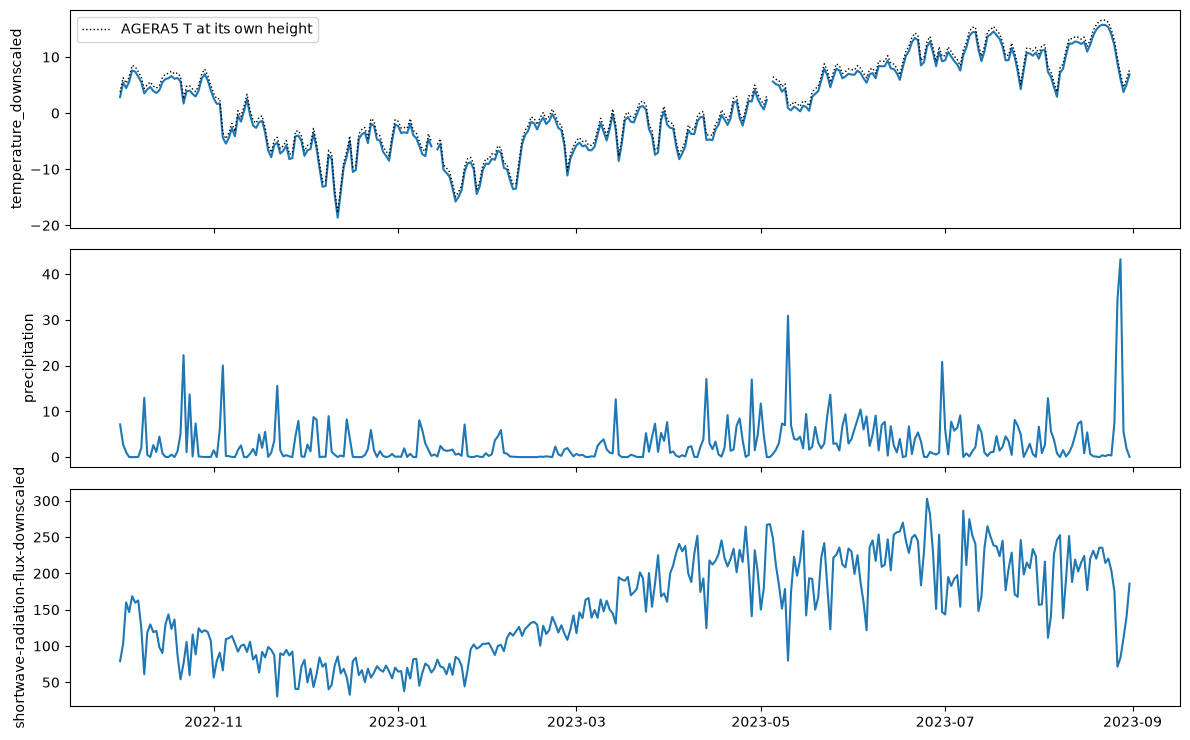

In [7]:
if have('swe_meteo'):
    met = ds['swe_meteo']
    print(met)
    met_mean = met.mean(['x', 'y'])
    fig, axes = plt.subplots(len(met.data_vars), 1, figsize=(12, 2.5 * len(met.data_vars)), sharex=True)
    for ax, v in zip(np.atleast_1d(axes), met.data_vars):
        ax.plot(met.t, met_mean[v]); ax.set_ylabel(v)
    if ds['raw_agera5'] is not None:
        np.atleast_1d(axes)[0].plot(ag.t, t_c, 'k:', lw=1, label='AGERA5 T at its own height')
        np.atleast_1d(axes)[0].legend()
    plt.tight_layout()
    for v in met.data_vars:
        a = met[v].values
        print(f'{v}: {np.nanmin(a):.2f}..{np.nanmax(a):.2f}, mean {np.nanmean(a):.2f}, NaN share {np.isnan(a).mean():.2f}')


using offline merge of snow + modis_scf + cp_occ
{'t': 188, 'x': 79, 'y': 79} | bands: ['snow', 'scf', 'cp_scf_0_10'] ... 10 cp, 10 occ
days with an HR image: 131 of 188
snow value counts: {np.float32(-1.0): np.int64(355737), np.float32(0.0): np.int64(79822), np.float32(100.0): np.int64(72220), np.float32(205.0): np.int64(665529)}
cp range: 0.0 1.0 | occ range: 0.0 17.0


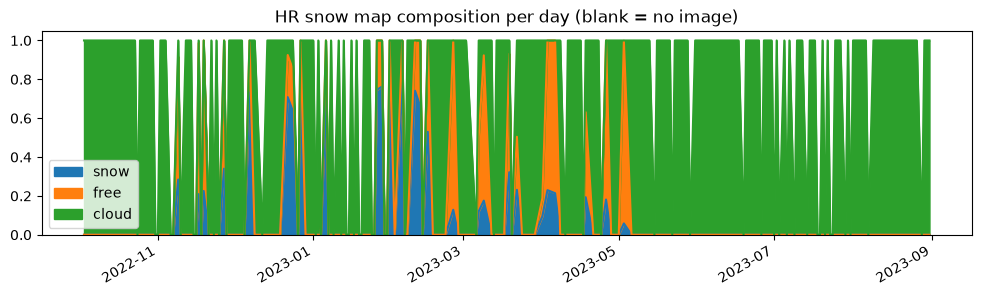

In [8]:
def combine_sca_inputs(snow_ds, scf_ds, cp_occ_ds):
    """Offline equivalent of snow_cover_area_inputs: snow + MODIS scf on the snow grid, cp/occ at the first date only."""
    times = np.union1d(snow_ds.t.values, scf_ds.t.values)
    grid = dict(x=snow_ds.x, y=snow_ds.y)
    snow_t = snow_ds[['snow']].reindex(t=times)
    scf_t = scf_ds[['scf']].interp(**grid, method='nearest').reindex(t=times)
    cp_occ_t = cp_occ_ds.squeeze(drop=True).interp(**grid, method='nearest').expand_dims(t=times[:1]).reindex(t=times)
    return xr.merge([snow_t, scf_t, cp_occ_t])


si = None
if ds['sca_inputs'] is not None:
    si = ds['sca_inputs']
    print('using backend-merged sca_inputs')
elif have('snow', 'modis_scf', 'cp_occ'):
    si = combine_sca_inputs(ds['snow'], ds['modis_scf'], ds['cp_occ'])
    print('using offline merge of snow + modis_scf + cp_occ')

if si is not None:
    snow = si['snow'].values if 'snow' in si else si[list(si.data_vars)[0]].values
    cp_vars = [v for v in si.data_vars if v.startswith('cp_')]
    occ_vars = [v for v in si.data_vars if v.startswith('occ_')]
    print(f'{dict(si.sizes)} | bands: {list(si.data_vars)[:3]} ... {len(cp_vars)} cp, {len(occ_vars)} occ')
    day_cls = pd.DataFrame({'no image (all NaN)': np.isnan(snow).all((1, 2)),
                            'snow': (snow == 100).mean((1, 2)), 'free': (snow == 0).mean((1, 2)), 'cloud': (snow == 205).mean((1, 2))},
                           index=si.t.values)
    print('days with an HR image:', int((~day_cls['no image (all NaN)']).sum()), 'of', len(day_cls))
    print('snow value counts:', dict(zip(*np.unique(np.nan_to_num(snow, nan=-1), return_counts=True))))
    t0 = si.isel(t=0)
    print('cp range:', float(np.nanmin(t0[cp_vars].to_array())), float(np.nanmax(t0[cp_vars].to_array())),
          '| occ range:', float(np.nanmin(t0[occ_vars].to_array())), float(np.nanmax(t0[occ_vars].to_array())))
    day_cls[['snow', 'free', 'cloud']].plot.area(figsize=(12, 3), title='HR snow map composition per day (blank = no image)');


## 3. UDFs run locally on the CDSE inputs, compared with the backend

In [9]:
def composition(a):
    a = np.asarray(a)
    return pd.Series({'snow': (a == 100).mean(), 'free': (a == 0).mean(), 'cloud': (a == 205).mean(), 'nodata': (a == 255).mean()})


sca_local = None
sca_backend = ds['sca'][list(ds['sca'].data_vars)[0]] if ds['sca'] is not None else None
if si is not None:
    order = ['snow', 'scf'] + cp_vars + occ_vars
    sca_in = si[order].to_array('bands').transpose('t', 'bands', 'y', 'x').astype('float32')
    sca_local = run_udf(SCA_UDF, sca_in, {'lr_pixel_size': 500}).isel(bands=0)
    comp = pd.DataFrame({'input': composition(np.nan_to_num(snow, nan=205)), 'local UDF': composition(sca_local.values)})
    if sca_backend is not None:
        comp['backend UDF'] = composition(sca_backend.values)
        common = np.intersect1d(sca_local.t.values, sca_backend.t.values)
        same = (sca_local.sel(t=common).values == sca_backend.sel(t=common).values).mean()
        print(f'local vs backend agreement on {len(common)} common days: {same:.3f}')
    display(comp)
else:
    print('SKIPPED local SCA: no SCA inputs')


,input,local UDF
snow,0.061552,0.112097
free,0.068032,0.270038
cloud,0.870416,0.617865
nodata,0.000000,0.000000


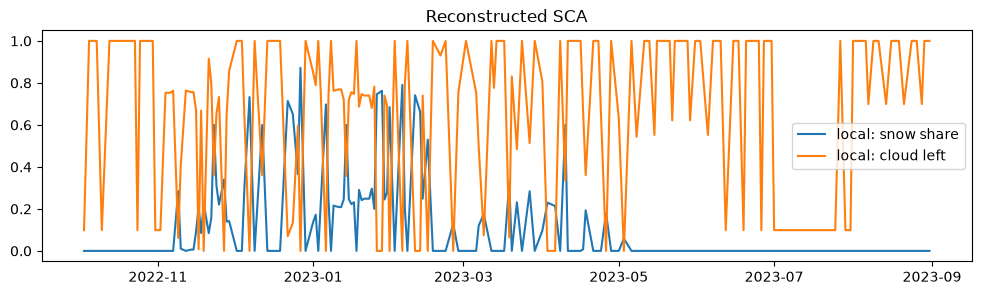

In [10]:
if sca_local is not None or sca_backend is not None:
    fig, ax = plt.subplots(figsize=(12, 3))
    if sca_local is not None:
        ax.plot(sca_local.t, (sca_local == 100).mean(['x', 'y']), label='local: snow share')
        ax.plot(sca_local.t, (sca_local == 205).mean(['x', 'y']), label='local: cloud left')
    if sca_backend is not None:
        ax.plot(sca_backend.t, (sca_backend == 100).mean(['x', 'y']), '--', label='backend: snow share')
    ax.legend(); ax.set_title('Reconstructed SCA');
else:
    print('SKIPPED: no SCA result')


SWE with unscaled slope (pipeline as-is): peak 0 mm, AOI-mean peak 0 mm
local SWE: peak 0 mm, AOI-mean peak 0 mm on 2022-10-03, NaN share 0.73


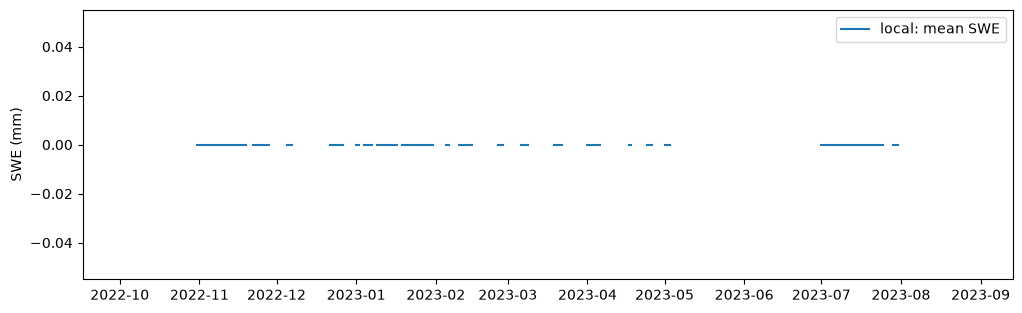

In [12]:
# SWE UDF with bands [sca, ta, pr, sw]. SCA = local SCA UDF result; without it, a MODIS proxy
# (scf >= 50 -> 100, < 50 -> 0, cloud/no MODIS image -> nearest clear day) on the 20 m modis_scf grid.
swe_local = None
swe_backend = ds['swe'][list(ds['swe'].data_vars)[0]] if ds['swe'] is not None else None
sca_for_swe = sca_local
if sca_for_swe is None and have('modis_scf', 'swe_meteo'):
    scf_daily = ds['modis_scf']['scf'].reindex(t=ds['swe_meteo'].t.values)
    sca_for_swe = xr.where(scf_daily > 100, 205, xr.where(scf_daily >= 50, 100, 0)).where(scf_daily.notnull(), 205)
    print(f'SCA = MODIS proxy (no local SCA result); MODIS days per month: {ds["modis_scf"].t.dt.month.to_series().value_counts().sort_index().to_dict()}')
    print(f'  share 205 before gap filling: {float((sca_for_swe == 205).mean()):.2f}')
    # The SWE UDF needs consecutive clear days (melt-out = 100 -> 0 from one day to the next), which the SCA
    # reconstruction provides; here gaps get the nearest clear day of the same pixel instead.
    sca_for_swe = sca_for_swe.where(sca_for_swe != 205).interpolate_na('t', method='nearest', fill_value='extrapolate').fillna(205)


def met_on(grid, met, sw_name='shortwave-radiation-flux-downscaled'):
    """Nearest DEM-grid (EPSG:4326) meteo pixel for each UTM 32N grid pixel."""
    lon, lat = Transformer.from_crs('EPSG:32632', 'EPSG:4326', always_xy=True).transform(*np.meshgrid(grid.x.values, grid.y.values))
    pts = dict(x=xr.DataArray(lon, dims=('y', 'x')), y=xr.DataArray(lat, dims=('y', 'x')))
    met = met.reindex(t=grid.t.values).sel(**pts, method='nearest').assign_coords(x=grid.x.values, y=grid.y.values)
    return [met[v] for v in ('temperature_downscaled', 'precipitation', sw_name)]


def run_swe(sca, met_vars):
    sca = sca.drop_vars('bands', errors='ignore')  # scalar coord left by isel(bands=0)
    swe_in = xr.concat([sca.astype('float32')] + list(met_vars), dim=pd.Index(['sca', 'ta', 'pr', 'sw'], name='bands'))
    return run_udf(SWE_UDF, swe_in.transpose('t', 'bands', 'y', 'x')).isel(bands=0)


if sca_for_swe is not None and have('swe_meteo'):
    met = ds['swe_meteo']
    swe_local = run_swe(sca_for_swe, met_on(sca_for_swe, met))
    if 'sw_as_is' in globals():
        swe_as_is = run_swe(sca_for_swe, met_on(sca_for_swe, met.assign(sw_as_is=sw_as_is), 'sw_as_is'))
        print(f'SWE with unscaled slope (pipeline as-is): peak {float(swe_as_is.max()):.0f} mm, '
              f'AOI-mean peak {float(swe_as_is.mean(["x", "y"]).max()):.0f} mm')
else:
    print('SKIPPED local SWE: no SCA and no meteo')

if swe_local is not None or swe_backend is not None:
    fig, ax = plt.subplots(figsize=(12, 3.5))
    if swe_local is not None:
        swe_mean = swe_local.mean(['x', 'y'])
        ax.plot(swe_local.t, swe_mean, label='local: mean SWE')
        print(f'local SWE: peak {float(swe_local.max()):.0f} mm, AOI-mean peak {float(swe_mean.max()):.0f} mm on '
              f'{str(swe_mean.idxmax().values)[:10]}, NaN share {float(swe_local.isnull().mean()):.2f}')
    if swe_backend is not None:
        ax.plot(swe_backend.t, swe_backend.mean(['x', 'y']), '--', label='backend: mean SWE')
        print(f'backend SWE: peak {float(swe_backend.max()):.0f} mm, NaN share {float(swe_backend.isnull().mean()):.2f}')
    ax.set_ylabel('SWE (mm)'); ax.legend()
